In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/heart_failure_clinical_records_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [3]:
df['DEATH_EVENT'].value_counts()

DEATH_EVENT
0    203
1     96
Name: count, dtype: int64

## Dataset Overview

This project uses the Heart Failure Clinical Records dataset. It contains 299 patient records and 13 columns describing clinical characteristics and the recorded outcome during follow-up.

### Column descriptions

- age: Age of the patient.
- anaemia: Whether anaemia was present (0 = No, 1 = Yes).
- creatinine_phosphokinase: Level of the CPK enzyme in the blood.
- diabetes: Whether diabetes was present (0 = No, 1 = Yes).
- ejection_fraction: Percentage of blood leaving the heart with each contraction.
- high_blood_pressure: Whether high blood pressure was present (0 = No, 1 = Yes).
- platelets: Platelet count in the blood.
- serum_creatinine: Serum creatinine level.
- serum_sodium: Serum sodium level.
- sex: Sex indicator as encoded in the dataset (0 or 1).
- smoking: Smoking indicator (0 = No, 1 = Yes).
- time: Follow-up period in days.
- DEATH_EVENT: Recorded outcome (0 = death event not recorded, 1 = death event recorded).

### Initial inspection

The dataset has 299 rows and 13 columns. Each column contains 299 non-missing values. The target variable has 203 records with DEATH_EVENT = 0 and 96 records with DEATH_EVENT = 1.

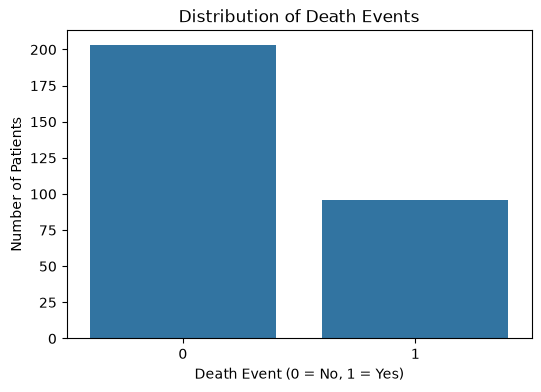

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='DEATH_EVENT')
plt.title('Distribution of Death Events')
plt.xlabel('Death Event (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

In [9]:

print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())


age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Duplicate rows: 0


In [10]:

binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']

for col in binary_cols:
    print(col, df[col].unique())


anaemia [0 1]
diabetes [0 1]
high_blood_pressure [1 0]
sex [1 0]
smoking [0 1]
DEATH_EVENT [1 0]


In [11]:

df.describe().T


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0



### Data Quality Summary

The dataset contains 299 rows and 13 columns, with zero missing values and zero duplicate rows. All six checked binary columns contain only 0 and 1. The age values range from 40 to 95, and ejection fraction ranges from 14 to 80, so neither shows an impossible value in these checks. Some measurements, such as serum sodium and platelet count, may be unusual, but they should be investigated rather than automatically removed.



## Descriptive Statistics


In [12]:

cont_cols = [
    'age',
    'creatinine_phosphokinase',
    'ejection_fraction',
    'platelets',
    'serum_creatinine',
    'serum_sodium'
]

stats = pd.DataFrame({
    'mean': df[cont_cols].mean(),
    'median': df[cont_cols].median(),
    'mode': df[cont_cols].mode().iloc[0],
    'variance': df[cont_cols].var(),
    'std': df[cont_cols].std(),
    'min': df[cont_cols].min(),
    'max': df[cont_cols].max(),
    'skewness': df[cont_cols].skew()
})

stats.round(2)


,mean,median,mode,variance,std,min,max,skewness
age,60.83,60.0,60.00,1.414900e+02,11.89,40.0,95.0,0.42
creatinine_phosphokinase,581.84,250.0,582.00,9.414586e+05,970.29,23.0,7861.0,4.46
ejection_fraction,38.08,38.0,35.00,1.400600e+02,11.83,14.0,80.0,0.56
platelets,263358.03,262000.0,263358.03,9.565669e+09,97804.24,25100.0,850000.0,1.46
serum_creatinine,1.39,1.1,1.00,1.070000e+00,1.03,0.5,9.4,4.46
serum_sodium,136.63,137.0,136.00,1.947000e+01,4.41,113.0,148.0,-1.05


In [13]:

stats[['mean', 'median', 'skewness']].round(2)


,mean,median,skewness
age,60.83,60.0,0.42
creatinine_phosphokinase,581.84,250.0,4.46
ejection_fraction,38.08,38.0,0.56
platelets,263358.03,262000.0,1.46
serum_creatinine,1.39,1.1,4.46
serum_sodium,136.63,137.0,-1.05



### Interpretation of Descriptive Statistics

The descriptive statistics show that creatinine_phosphokinase and serum_creatinine are strongly right-skewed, with skewness values of 4.46 for both variables. Their means are higher than their medians, indicating that some large values pull the means upward. Platelets also show right skewness (1.46), whereas serum_sodium shows left skewness (-1.05). Skewness describes the asymmetry of a distribution. In a later step, we will investigate suitable transformations for highly skewed variables.



## Outlier Analysis


In [14]:

rows = []

for c in cont_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1

    lo = q1 - 1.5 * iqr
    hi = q3 + 1.5 * iqr

    n_iqr = ((df[c] < lo) | (df[c] > hi)).sum()

    z = (df[c] - df[c].mean()) / df[c].std()
    n_z = (z.abs() > 3).sum()

    rows.append([c, q1, q3, iqr, lo, hi, n_iqr, n_z])

outliers = pd.DataFrame(
    rows,
    columns=[
        'column', 'Q1', 'Q3', 'IQR', 'lower', 'upper',
        'IQR_outliers', 'Z>3_outliers'
    ]
).set_index('column')

outliers.round(2)


,Q1,Q3,IQR,lower,upper,IQR_outliers,Z>3_outliers
column,,,,,,,
age,51.0,70.0,19.0,22.50,98.50,0,0
creatinine_phosphokinase,116.5,582.0,465.5,-581.75,1280.25,29,7
ejection_fraction,30.0,45.0,15.0,7.50,67.50,2,1
platelets,212500.0,303500.0,91000.0,76000.00,440000.00,21,3
serum_creatinine,0.9,1.4,0.5,0.15,2.15,29,6
serum_sodium,134.0,140.0,6.0,125.00,149.00,4,3


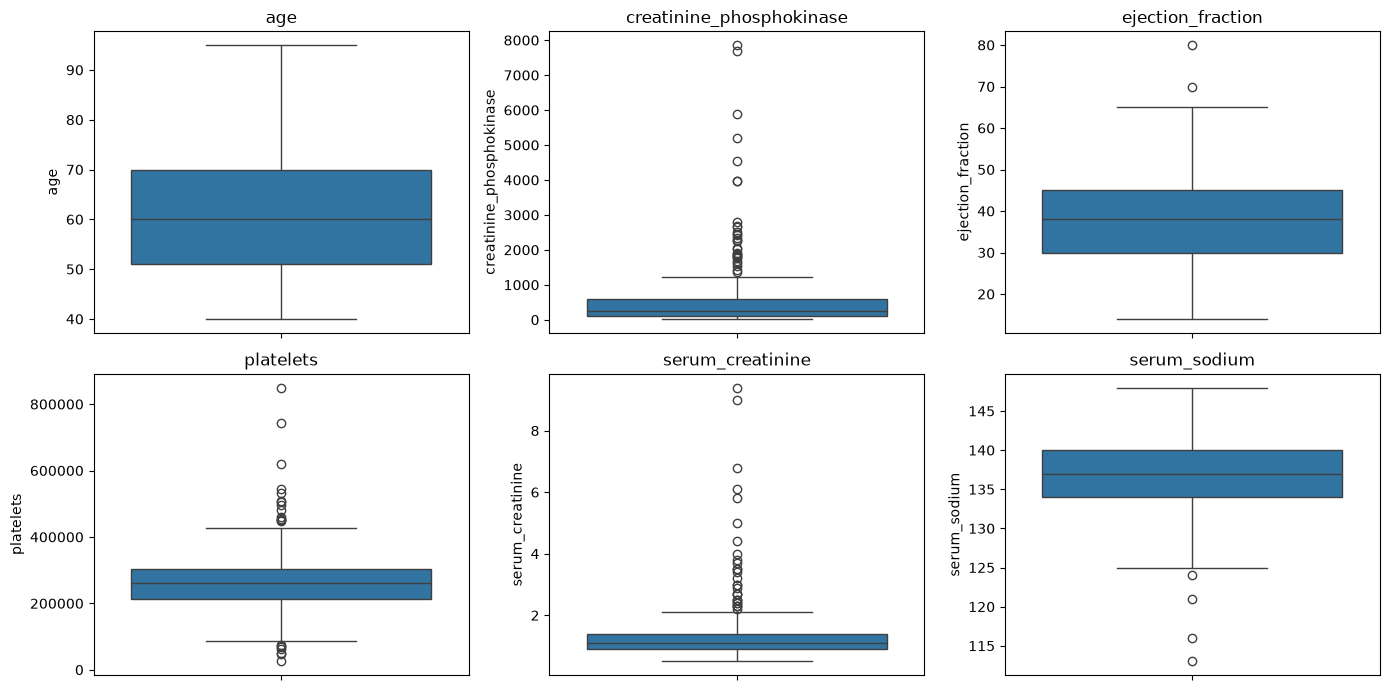

In [15]:

fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for ax, c in zip(axes.ravel(), cont_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)

plt.tight_layout()
plt.show()


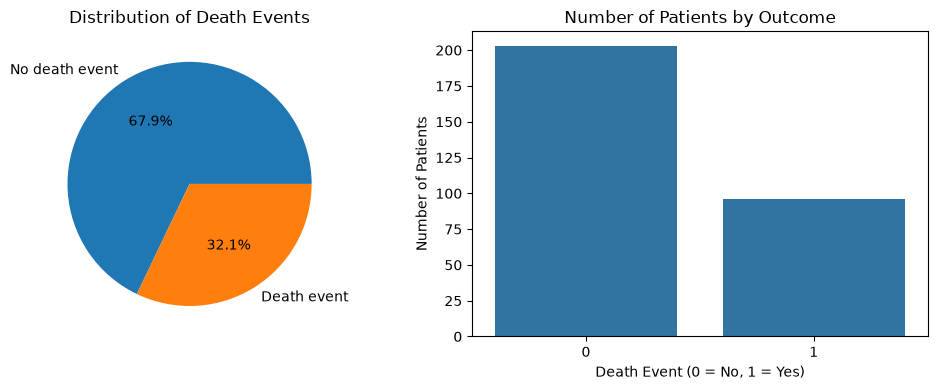

In [16]:

# Visualisation 1: Target distribution

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

df['DEATH_EVENT'].value_counts().sort_index().plot.pie(
    autopct='%1.1f%%',
    labels=['No death event', 'Death event'],
    ax=ax[0]
)
ax[0].set_title('Distribution of Death Events')
ax[0].set_ylabel('')

sns.countplot(x='DEATH_EVENT', data=df, ax=ax[1])
ax[1].set_title('Number of Patients by Outcome')
ax[1].set_xlabel('Death Event (0 = No, 1 = Yes)')
ax[1].set_ylabel('Number of Patients')

plt.tight_layout()
plt.show()


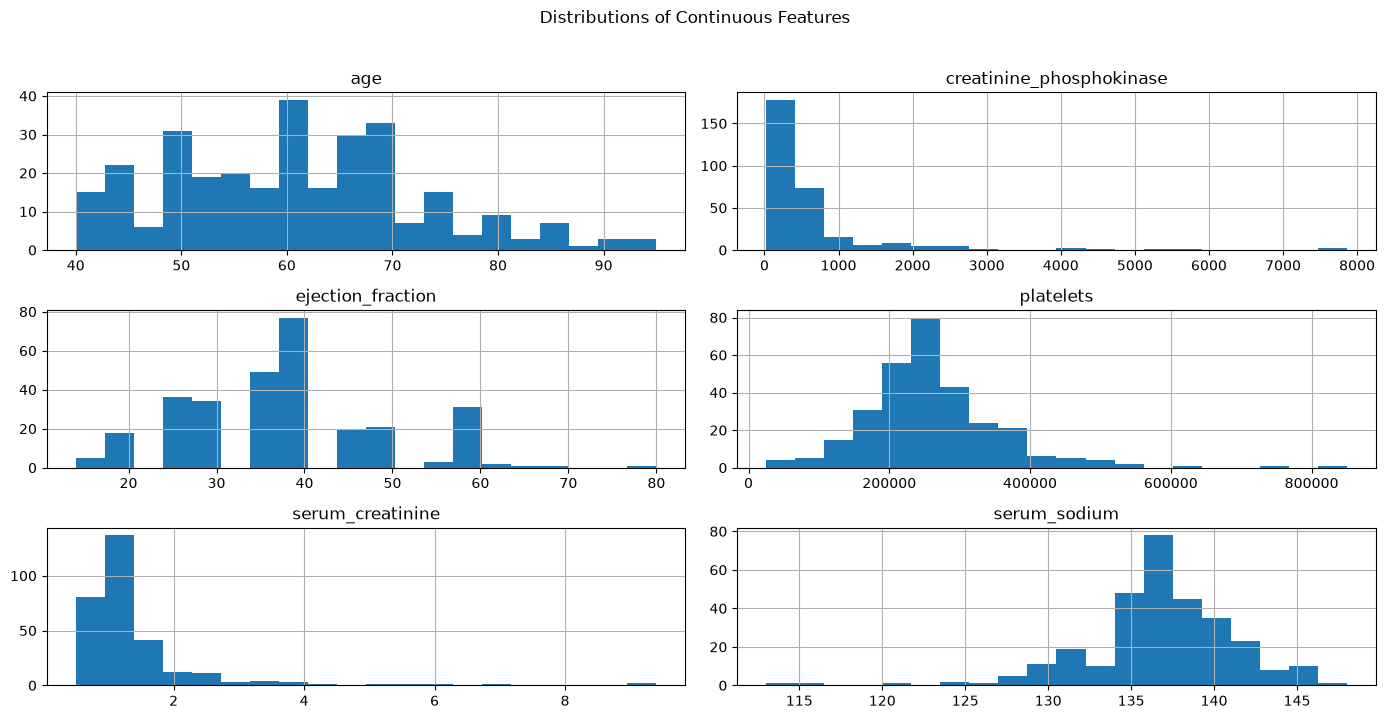

In [17]:

# Visualisation 2: Histograms of continuous features

df[cont_cols].hist(bins=20, figsize=(14, 7))
plt.suptitle('Distributions of Continuous Features', y=1.02)
plt.tight_layout()
plt.show()


### Interpretation of Histograms

The histograms illustrate the distributions of the six continuous features in the dataset.

- **Age:** Most patients are between 50 and 70 years old.
- **Creatinine Phosphokinase:** The distribution is strongly right-skewed, with a long tail toward higher values.
- **Ejection Fraction:** Most observations are concentrated between approximately 30 and 45.
- **Platelets:** Most platelet counts fall between approximately 200,000 and 350,000, although some values are considerably higher.
- **Serum Creatinine:** The distribution is strongly right-skewed, with a small number of observations having high values.
- **Serum Sodium:** Most observations are concentrated between approximately 135 and 140.

**Conclusion:** Creatinine phosphokinase and serum creatinine exhibit strong right skewness, while platelet counts also show some right skewness. These patterns will be considered during feature engineering, where log transformations will be applied to creatinine phosphokinase and serum creatinine to reduce their skewness.

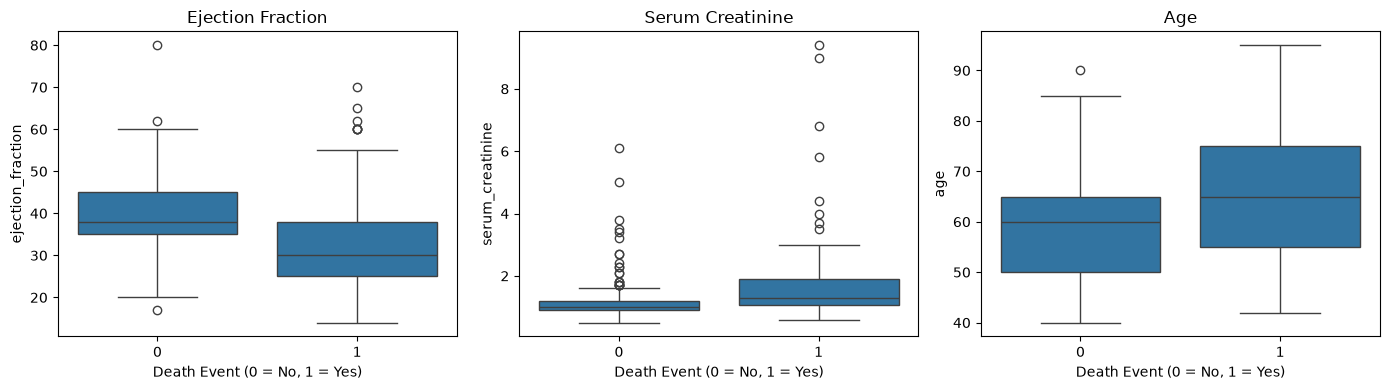

In [18]:

# Visualisation 3: Continuous features by outcome

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, c in zip(axes, ['ejection_fraction', 'serum_creatinine', 'age']):
    sns.boxplot(x='DEATH_EVENT', y=c, data=df, ax=ax)
    ax.set_title(c.replace('_', ' ').title())
    ax.set_xlabel('Death Event (0 = No, 1 = Yes)')

plt.tight_layout()
plt.show()


### Interpretation of Boxplots by Outcome

The boxplots compare ejection fraction, serum creatinine, and age across the two outcome groups.

- **Ejection Fraction:** The group with a recorded death event generally has a lower median ejection fraction than the group without a recorded death event.
- **Serum Creatinine:** The median serum creatinine level is higher in the death-event group, indicating an association between higher values and the recorded outcome.
- **Age:** The death-event group has a higher median age than the other group.

**Conclusion:** These visualisations suggest that lower ejection fraction, higher serum creatinine, and older age are associated with the recorded death outcome in this dataset. These relationships will be explored further during model development.

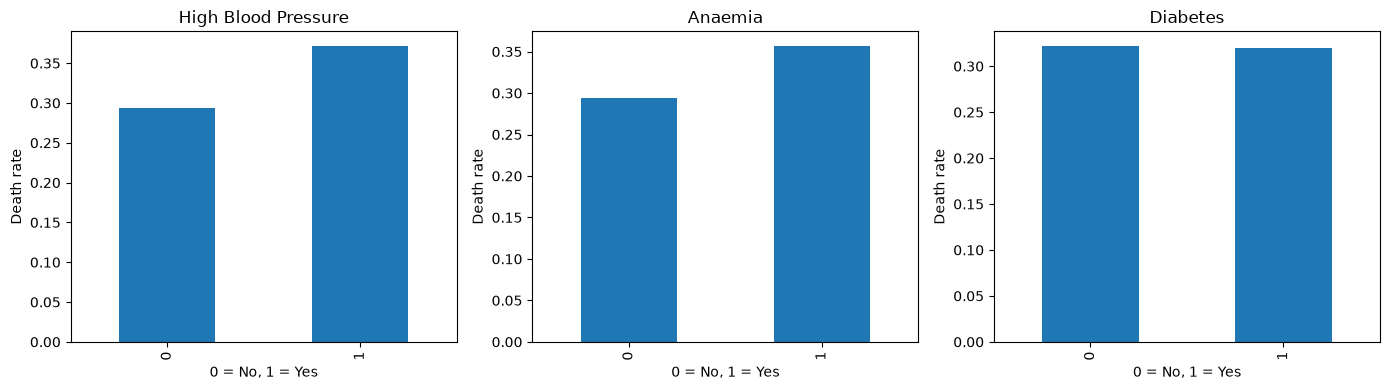

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, c in zip(axes, ['high_blood_pressure', 'anaemia', 'diabetes']):
    df.groupby(c)['DEATH_EVENT'].mean().plot.bar(ax=ax)
    ax.set_ylabel('Death rate')
    ax.set_title(c.replace('_', ' ').title())
    ax.set_xlabel('0 = No, 1 = Yes')

plt.tight_layout()
plt.show()

### Interpretation of Death Rates by Binary Features

- **High Blood Pressure:** Patients with high blood pressure show a higher recorded death-event rate than patients without it.
- **Anaemia:** The death-event rate is slightly higher among patients with anaemia.
- **Diabetes:** The death-event rates are nearly identical for patients with and without diabetes.

**Conclusion:** High blood pressure and anaemia show some differences in death-event rates, while diabetes shows little difference in this dataset. These observations describe associations and will be explored further during model development.

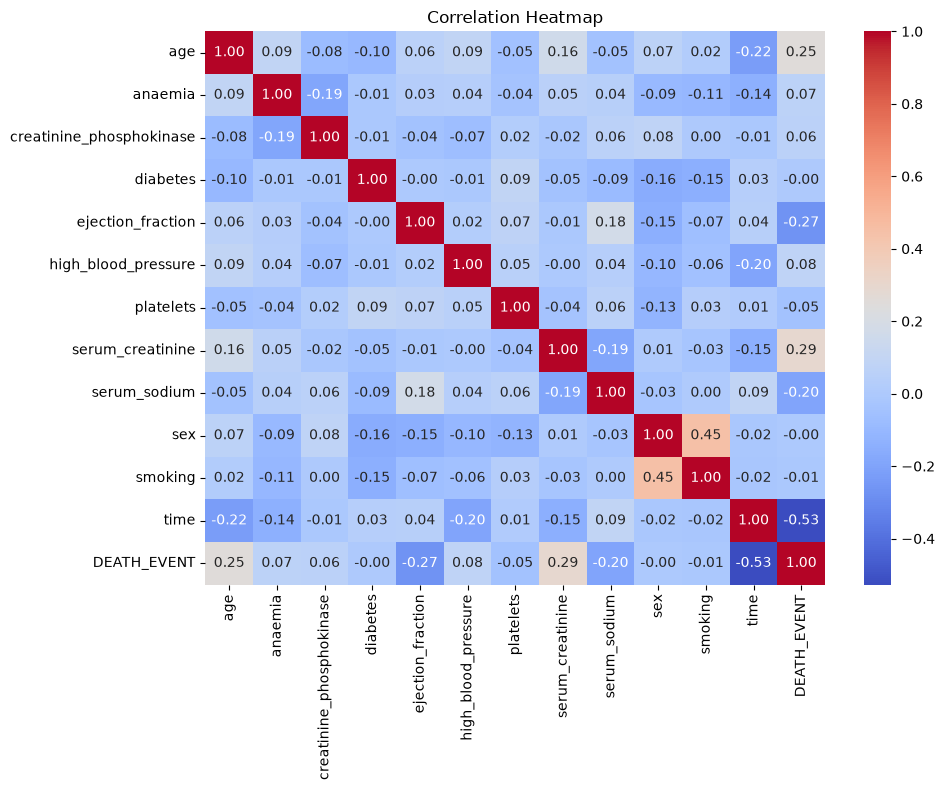

In [20]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Interpretation of Correlation Heatmap

The correlation heatmap shows the relationships between the numerical features and the recorded death-event outcome.

- **Time (-0.53):** Shows the strongest correlation with `DEATH_EVENT`. This relationship supports excluding `time` from the prediction features because it represents the follow-up period.
- **Serum Creatinine (+0.29):** Shows a positive association with the recorded death-event outcome.
- **Ejection Fraction (-0.27):** Shows a negative association, indicating that lower values tend to occur alongside more recorded death events.
- **Age (+0.25):** Shows a positive association with the recorded outcome.
- **Serum Sodium (-0.20):** Shows a negative association with the recorded outcome.

**Conclusion:** Most features have relatively weak linear correlations with the target. Correlation alone does not determine which features are useful for prediction, so their importance will also be evaluated during model development.

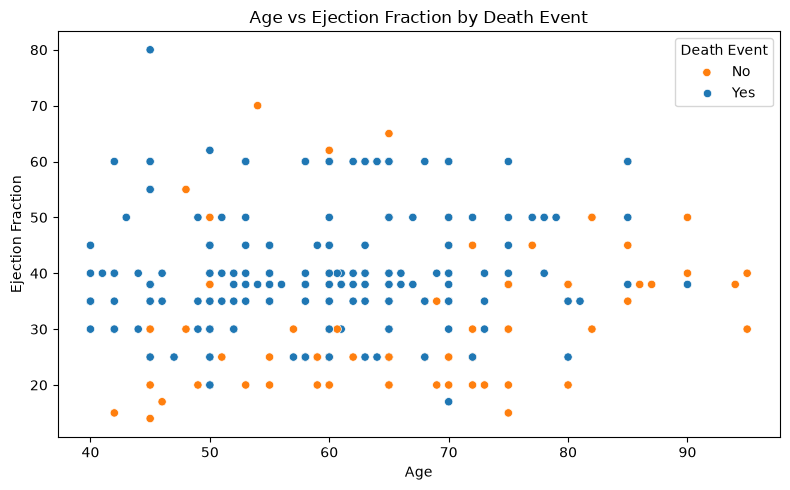

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x='age',
    y='ejection_fraction',
    hue='DEATH_EVENT',
    data=df
)

plt.title('Age vs Ejection Fraction by Death Event')
plt.xlabel('Age')
plt.ylabel('Ejection Fraction')
plt.legend(title='Death Event', labels=['No', 'Yes'])
plt.tight_layout()
plt.show()

### Interpretation of Age vs Ejection Fraction

The scatter plot shows the relationship between patient age and ejection fraction, with points distinguished by the recorded death-event outcome. The two groups may overlap, but the plot helps us examine how these features vary together. Combined with the earlier boxplots, it supports further investigation of age and ejection fraction during model development.

**Conclusion:** No single feature perfectly separates the two outcome groups, so multiple features will be considered when training the prediction models.

## Feature Engineering and Selection

Feature engineering involves preparing the dataset so that machine-learning models can learn useful patterns. In this step, the follow-up `time` column will be excluded from the prediction features to reduce the risk of information leakage. We will also apply logarithmic transformations to highly right-skewed features and examine feature correlations with the target variable.

In [22]:
df_clean = df.drop(columns=['time']).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

df_clean.head()

Original dataset shape: (299, 13)
Cleaned dataset shape: (299, 12)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,1


In [23]:
for c in ['creatinine_phosphokinase', 'serum_creatinine']:
    df_clean[c] = np.log1p(df_clean[c])

print("Skewness after log transformation:")
print(df_clean[['creatinine_phosphokinase', 'serum_creatinine']].skew().round(2))

Skewness after log transformation:
creatinine_phosphokinase    0.42
serum_creatinine            2.31
dtype: float64


In [24]:
corr_rank = (
    df_clean.corr()['DEATH_EVENT']
    .drop('DEATH_EVENT')
    .abs()
    .sort_values(ascending=False)
)

corr_rank

serum_creatinine            0.346136
ejection_fraction           0.268603
age                         0.253729
serum_sodium                0.195204
high_blood_pressure         0.079351
anaemia                     0.066270
platelets                   0.049139
creatinine_phosphokinase    0.032048
smoking                     0.012623
sex                         0.004316
diabetes                    0.001943
Name: DEATH_EVENT, dtype: float64

## Interpretation of Feature Engineering and Selection

The log transformation reduced the skewness of `creatinine_phosphokinase` from 4.46 to 0.42 and `serum_creatinine` from 4.46 to 2.31. This indicates a substantial improvement in the distribution of both variables, although serum creatinine remains right-skewed.

Based on the absolute correlation ranking, serum creatinine, ejection fraction, and age show the strongest associations with the recorded death outcome. In contrast, sex, smoking, and diabetes show very weak linear correlations in this dataset.

All remaining features will be retained for model development because the dataset contains only 299 observations and these variables may still provide useful information when considered alongside other features. Correlation alone is not sufficient to determine a feature's predictive value.

The `time` column has been excluded from the cleaned dataset because it represents follow-up duration and has a strong association with the recorded outcome. Using it as a prediction feature could introduce information leakage. The original dataset remains unchanged.

In [25]:
df_clean.to_csv('../data/heart_clean.csv', index=False)

print("Cleaned dataset shape:", df_clean.shape)
print("Saved successfully!")

Cleaned dataset shape: (299, 12)
Saved successfully!
